In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install torch torchvision matplotlib scikit-learn seaborn tqdm --quiet

import torch
print(f'CUDA: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

CUDA: True
GPU: Tesla T4


In [3]:
from pathlib import Path

d = Path('/content/drive/MyDrive/lamoda_dataset')
image_ext = {'.jpg', '.jpeg', '.png', '.webp'}
total = 0
cats = 0
for sub in sorted(d.iterdir()):
    if sub.is_dir():
        n = len([f for f in sub.iterdir() if f.suffix.lower() in image_ext])
        if n > 0:
            cats += 1
            total += n
            print(f"  {sub.name:40s} {n:5d}")
print(f"\nВсего: {total} изображений, {cats} категорий")

  блузы_и_рубашки                            216
  боди                                       200
  брюки                                      228
  верхняя_одежда                             221
  джемперы_свитеры_кардиганы                  86
  джинсы                                      69
  домашняя_одежда                             59
  комбинезоны                                 67
  купальники                                  43
  нижнее_белье                                74
  пиджаки_и_костюмы                           92
  платья_и_сарафаны                           40
  пляжная_одежда                              22
  спортивные_костюмы                          61
  футболки_и_поло                             99
  худи_и_свитшоты                             60
  шорты                                       59
  юбки                                        52

Всего: 1748 изображений, 18 категорий


In [4]:
import os
import numpy as np
from collections import Counter
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset, WeightedRandomSampler
from torchvision import transforms, models
from torchvision.datasets import ImageFolder
from PIL import Image
from tqdm.notebook import tqdm

DATASET_DIR = '/content/drive/MyDrive/lamoda_dataset'
CHECKPOINTS_DIR = '/content/drive/MyDrive/lamoda_checkpoints'
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 30
LEARNING_RATE = 0.001
UNFREEZE_EPOCH = 5
MIN_IMAGES = 20

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Устройство: {DEVICE}')

train_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE + 32, IMAGE_SIZE + 32)),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.2),
])

val_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Датасет с переиндексацией меток
class FilteredDataset(Dataset):
    """Датасет с фильтрацией мелких категорий и переиндексацией меток."""
    def __init__(self, root, min_images=20):
        self.samples = []
        self.class_names = []
        self.targets = []

        image_ext = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
        root = Path(root)

        # Собираем категории с достаточным количеством изображений
        all_cats = sorted([
            d for d in root.iterdir()
            if d.is_dir() and len([f for f in d.iterdir() if f.suffix.lower() in image_ext]) >= min_images
        ])

        for new_label, cat_dir in enumerate(all_cats):
            self.class_names.append(cat_dir.name)
            for img_path in sorted(cat_dir.iterdir()):
                if img_path.suffix.lower() in image_ext:
                    self.samples.append((str(img_path), new_label))
                    self.targets.append(new_label)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        try:
            img = Image.open(path).convert('RGB')
        except Exception:
            img = Image.new('RGB', (224, 224), (128, 128, 128))
        return img, label

class TransformSubset(Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, idx):
        img, label = self.subset[idx]
        if self.transform and isinstance(img, Image.Image):
            img = self.transform(img)
        return img, label

# Загружаем
full_dataset = FilteredDataset(DATASET_DIR, min_images=MIN_IMAGES)
class_names = full_dataset.class_names
num_classes = len(class_names)

print(f'\nКлассов (>= {MIN_IMAGES} фото): {num_classes}')
print(f'Изображений: {len(full_dataset)}')

class_counts = Counter(full_dataset.targets)
for label, name in enumerate(class_names):
    print(f'  {name:40s} {class_counts[label]:5d}')

# Разбиение 70/15/15
indices = list(range(len(full_dataset)))
np.random.seed(42)
np.random.shuffle(indices)
n = len(indices)
n_train = int(0.70 * n)
n_val = int(0.15 * n)

train_idx = indices[:n_train]
val_idx = indices[n_train:n_train + n_val]
test_idx = indices[n_train + n_val:]

print(f'\nTrain: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}')

train_ds = TransformSubset(Subset(full_dataset, train_idx), train_transforms)
val_ds = TransformSubset(Subset(full_dataset, val_idx), val_transforms)
test_ds = TransformSubset(Subset(full_dataset, test_idx), val_transforms)

# Балансировка
train_targets = [full_dataset.targets[i] for i in train_idx]
tc = Counter(train_targets)
sample_weights = [len(train_targets) / (len(tc) * tc[t]) for t in train_targets]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights))

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler,
                          num_workers=2, pin_memory=True, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=2, pin_memory=True)

# Проверка: метки от 0 до num_classes-1
max_label = max(full_dataset.targets)
print(f'\nМетки: 0..{max_label}, классов в модели: {num_classes}')
assert max_label == num_classes - 1, f'ОШИБКА: макс метка {max_label} != {num_classes-1}'
print('Данные готовы')

Устройство: cuda

Классов (>= 20 фото): 18
Изображений: 1748
  блузы_и_рубашки                            216
  боди                                       200
  брюки                                      228
  верхняя_одежда                             221
  джемперы_свитеры_кардиганы                  86
  джинсы                                      69
  домашняя_одежда                             59
  комбинезоны                                 67
  купальники                                  43
  нижнее_белье                                74
  пиджаки_и_костюмы                           92
  платья_и_сарафаны                           40
  пляжная_одежда                              22
  спортивные_костюмы                          61
  футболки_и_поло                             99
  худи_и_свитшоты                             60
  шорты                                       59
  юбки                                        52

Train: 1223 | Val: 262 | Test: 263

Метки: 0..17, классо

In [5]:
class ClothingClassifier(nn.Module):
    def __init__(self, num_classes, pretrained=True):
        super().__init__()
        weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        self.backbone = models.efficientnet_b0(weights=weights)
        for p in self.backbone.parameters():
            p.requires_grad = False
        in_f = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(in_f, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        return self.backbone(x)

    def unfreeze(self, n_layers=4):
        for layer in list(self.backbone.features.children())[-n_layers:]:
            for p in layer.parameters():
                p.requires_grad = True

    def count_params(self):
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

model = ClothingClassifier(num_classes).to(DEVICE)
print(f'EfficientNet-B0 | {num_classes} классов | {model.count_params():,} обучаемых параметров')

EfficientNet-B0 | 18 классов | 666,130 обучаемых параметров


In [6]:
os.makedirs(CHECKPOINTS_DIR, exist_ok=True)

total_train = len(train_idx)
weights_list = []
for label in range(num_classes):
    cnt = class_counts[label]
    weights_list.append(total_train / (num_classes * cnt))
class_weights = torch.FloatTensor(weights_list).to(DEVICE)

print(f'Классов: {num_classes}, весов: {len(class_weights)}')

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE, weight_decay=1e-4
)
scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=10, T_mult=2, eta_min=1e-6
)

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'lr': []}
best_val_acc = 0.0
best_epoch = 0

for epoch in range(1, EPOCHS + 1):

    if epoch == UNFREEZE_EPOCH:
        print(f'\n-- Эпоха {epoch}: размораживаем backbone --')
        model.unfreeze(4)
        optimizer = optim.AdamW(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=optimizer.param_groups[0]['lr'] * 0.1, weight_decay=1e-4
        )
        scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(
            optimizer, T_0=10, T_mult=2, eta_min=1e-7
        )
        print(f'   Обучаемых параметров: {model.count_params():,}\n')

    model.train()
    run_loss, correct, total = 0.0, 0, 0
    for imgs, labels in tqdm(train_loader, desc=f'Эпоха {epoch}/{EPOCHS}', leave=False):
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        out = model(imgs)
        loss = criterion(out, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        run_loss += loss.item() * imgs.size(0)
        _, pred = out.max(1)
        total += labels.size(0)
        correct += pred.eq(labels).sum().item()
    train_loss = run_loss / total
    train_acc = correct / total

    model.eval()
    v_loss, v_correct, v_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            out = model(imgs)
            loss = criterion(out, labels)
            v_loss += loss.item() * imgs.size(0)
            _, pred = out.max(1)
            v_total += labels.size(0)
            v_correct += pred.eq(labels).sum().item()
    val_loss = v_loss / v_total
    val_acc = v_correct / v_total

    scheduler.step()
    lr = optimizer.param_groups[0]['lr']

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['lr'].append(lr)

    marker = ''
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        torch.save({
            'epoch': epoch, 'model_state_dict': model.state_dict(),
            'class_names': class_names, 'num_classes': num_classes,
            'val_acc': val_acc, 'history': history,
        }, f'{CHECKPOINTS_DIR}/best_model.pth')
        marker = ' <-- BEST'

    print(f'Эп {epoch:2d}/{EPOCHS} | '
          f'Train L:{train_loss:.4f} A:{train_acc:.4f} | '
          f'Val L:{val_loss:.4f} A:{val_acc:.4f} | '
          f'LR:{lr:.2e}{marker}')

print(f'\nЛучшая Val Accuracy: {best_val_acc:.4f} (эпоха {best_epoch})')

Классов: 18, весов: 18


Эпоха 1/30:   0%|          | 0/38 [00:00<?, ?it/s]

Эп  1/30 | Train L:2.0899 A:0.2845 | Val L:2.1055 A:0.2252 | LR:9.76e-04 <-- BEST


Эпоха 2/30:   0%|          | 0/38 [00:00<?, ?it/s]

Эп  2/30 | Train L:1.4402 A:0.4433 | Val L:1.7186 A:0.3053 | LR:9.05e-04 <-- BEST


...

Эп 28/30 | Train L:0.2829 A:0.8577 | Val L:0.9146 A:0.6565 | LR:1.36e-05


Эпоха 29/30:   0%|          | 0/38 [00:00<?, ?it/s]

Эп 29/30 | Train L:0.2656 A:0.8602 | Val L:0.9243 A:0.6641 | LR:9.68e-06 <-- BEST


Эпоха 30/30:   0%|          | 0/38 [00:00<?, ?it/s]

Эп 30/30 | Train L:0.2795 A:0.8503 | Val L:0.9231 A:0.6718 | LR:6.34e-06 <-- BEST

Лучшая Val Accuracy: 0.6718 (эпоха 30)


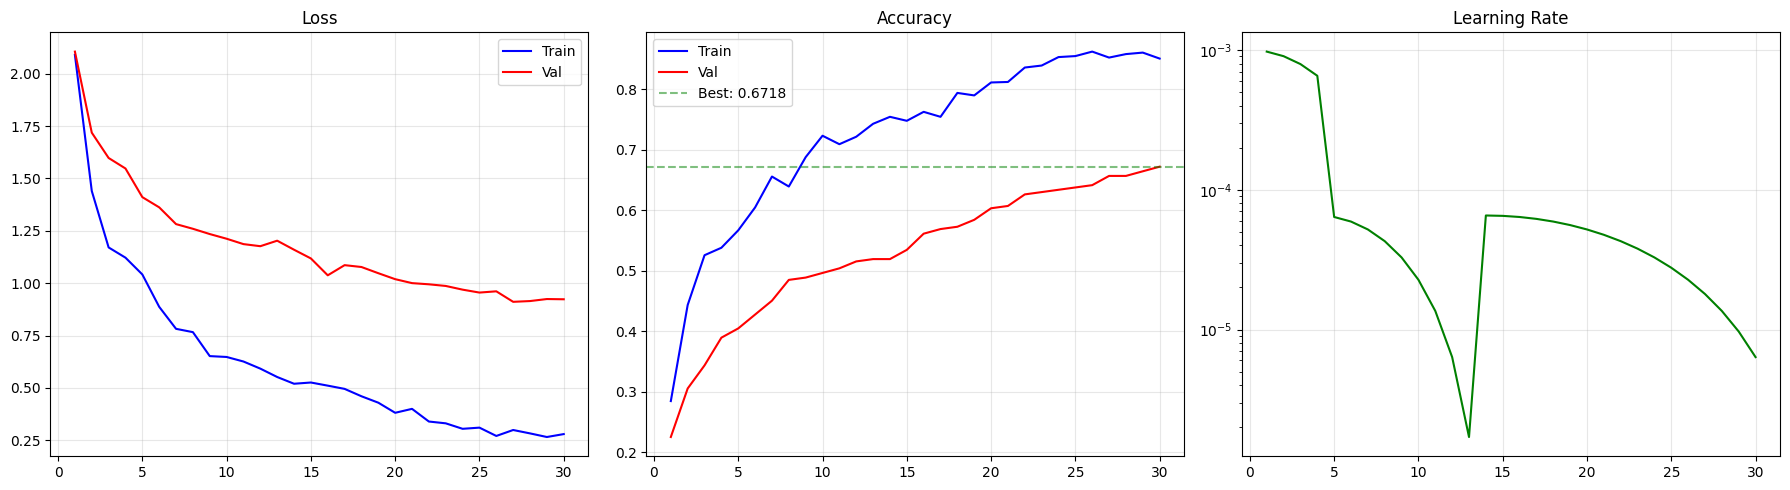

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ep = range(1, len(history['train_loss']) + 1)

axes[0].plot(ep, history['train_loss'], 'b-', label='Train')
axes[0].plot(ep, history['val_loss'], 'r-', label='Val')
axes[0].set_title('Loss'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(ep, history['train_acc'], 'b-', label='Train')
axes[1].plot(ep, history['val_acc'], 'r-', label='Val')
axes[1].axhline(y=best_val_acc, color='g', ls='--', alpha=0.5, label=f'Best: {best_val_acc:.4f}')
axes[1].set_title('Accuracy'); axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(ep, history['lr'], 'g-')
axes[2].set_title('Learning Rate'); axes[2].set_yscale('log'); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{CHECKPOINTS_DIR}/training_curves.png', dpi=150)
plt.show()

Тест:   0%|          | 0/9 [00:00<?, ?it/s]

                            precision    recall  f1-score   support

           блузы_и_рубашки     0.6667    0.4138    0.5106        29
                      боди     0.8421    0.5714    0.6809        28
                     брюки     0.8571    0.4286    0.5714        28
            верхняя_одежда     0.8400    0.5526    0.6667        38
джемперы_свитеры_кардиганы     0.4444    0.5714    0.5000         7
                    джинсы     0.4444    0.7273    0.5517        11
           домашняя_одежда     0.3333    0.3333    0.3333        12
               комбинезоны     0.3750    0.9000    0.5294        10
                купальники     0.6154    1.0000    0.7619         8
              нижнее_белье     0.8182    0.9000    0.8571        10
         пиджаки_и_костюмы     0.5385    0.5385    0.5385        13
         платья_и_сарафаны     0.4545    0.8333    0.5882         6
            пляжная_одежда     0.4000    0.5000    0.4444         8
        спортивные_костюмы     0.2692    0.8750

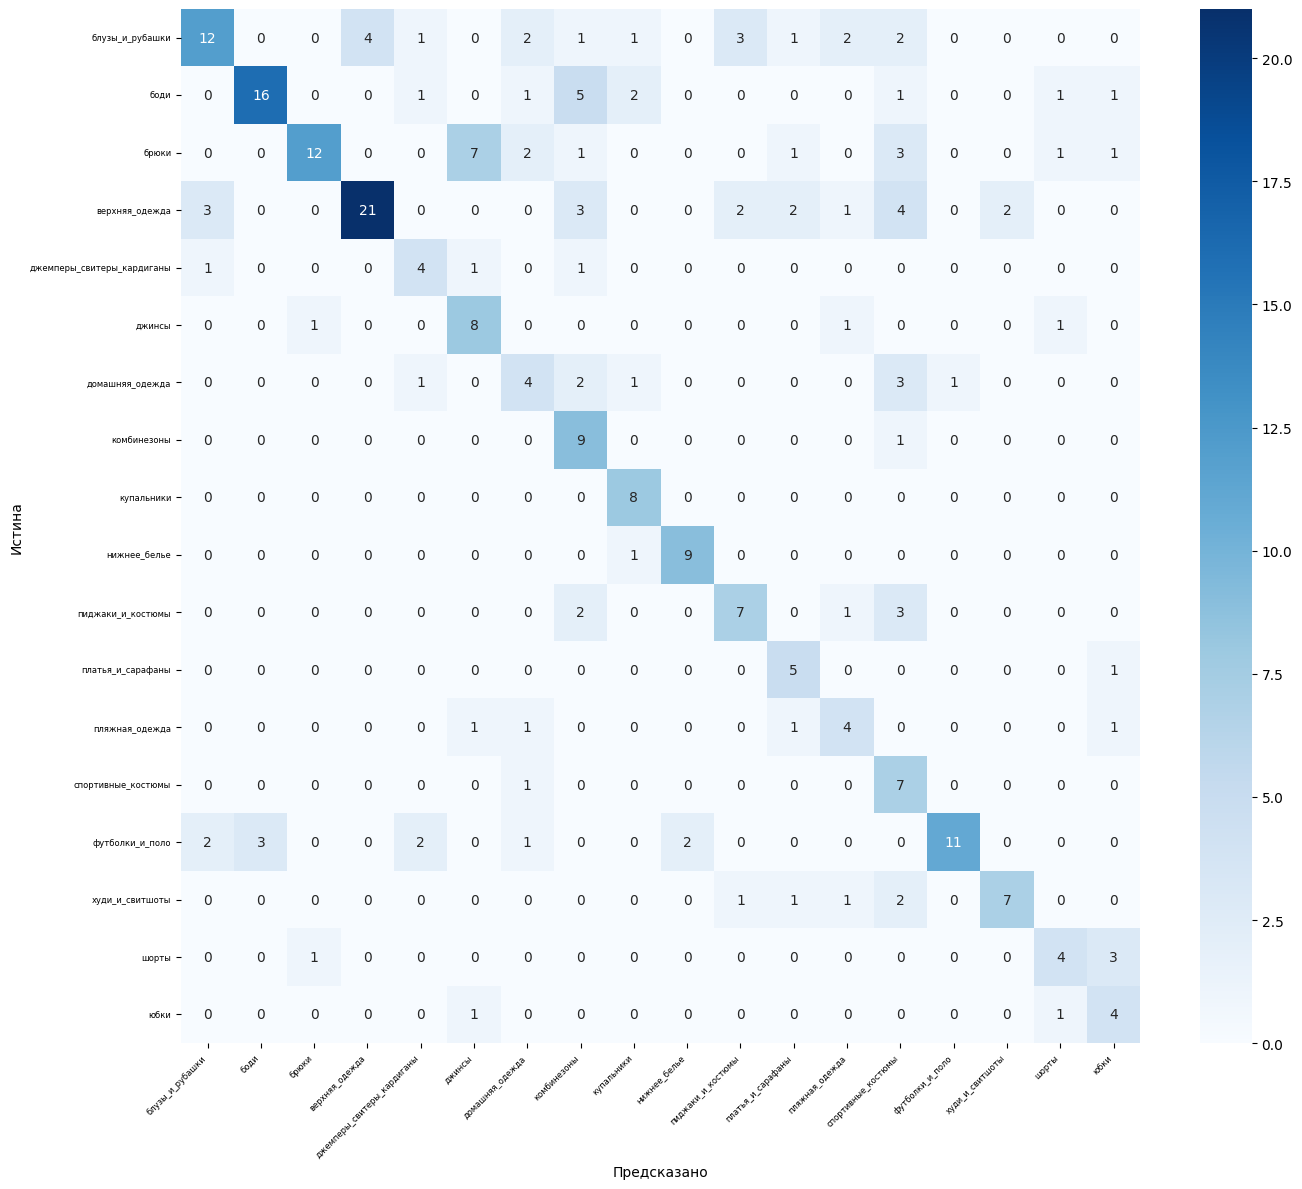

In [8]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

ckpt = torch.load(f'{CHECKPOINTS_DIR}/best_model.pth', map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc='Тест'):
        imgs = imgs.to(DEVICE)
        _, pred = model(imgs).max(1)
        all_preds.extend(pred.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(max(14, num_classes*0.5), max(12, num_classes*0.45)))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel('Предсказано'); ax.set_ylabel('Истина')
plt.xticks(rotation=45, ha='right', fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()
plt.savefig(f'{CHECKPOINTS_DIR}/confusion_matrix.png', dpi=150)
plt.show()

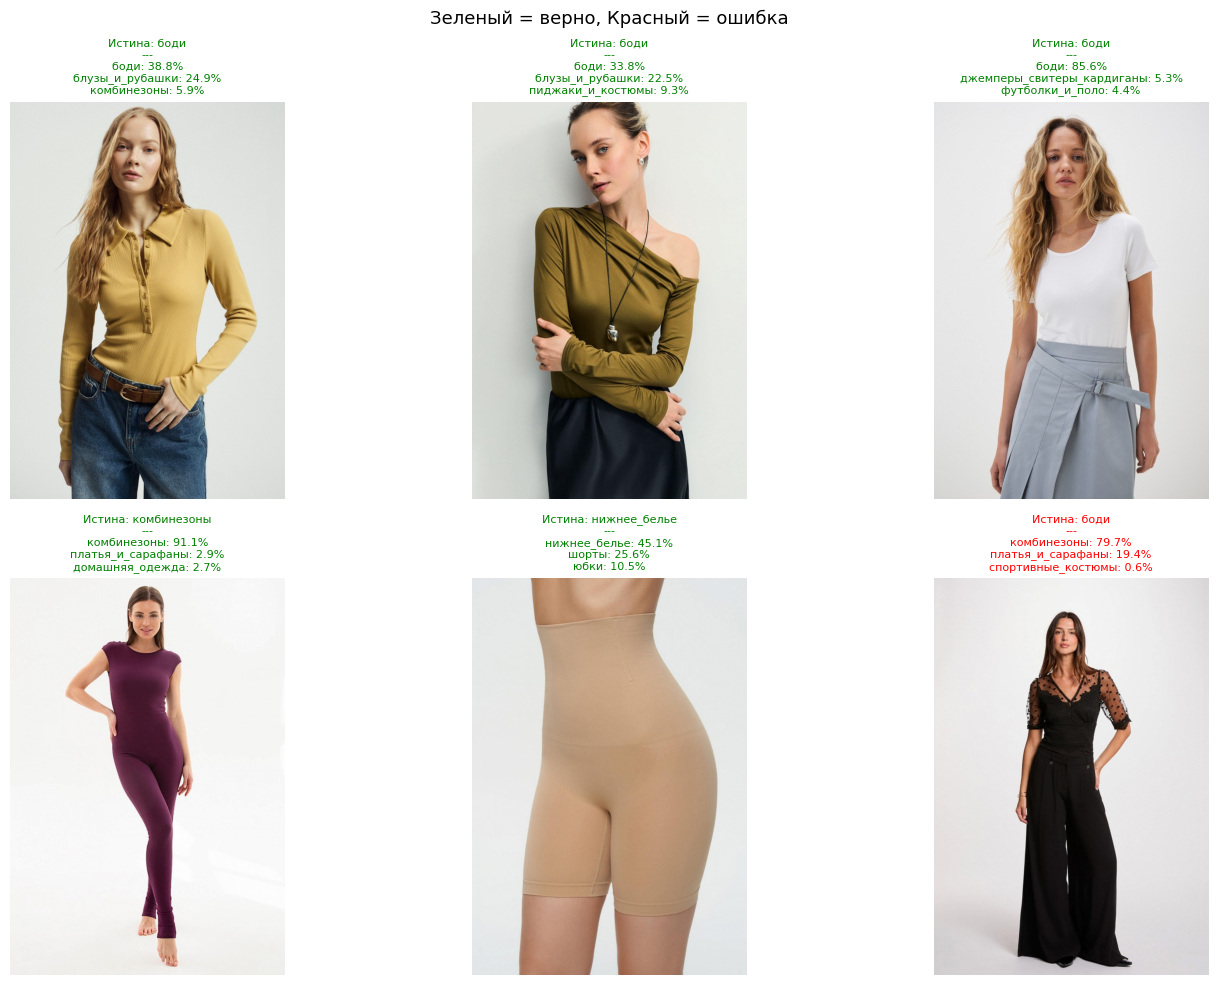

In [10]:
import matplotlib.pyplot as plt

sample_idx = np.random.choice(test_idx, size=6, replace=False)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, idx in zip(axes.flat, sample_idx):
    img_pil, label = full_dataset[idx]
    true_label = class_names[label]

    tensor = val_transforms(img_pil).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        probs = F.softmax(model(tensor), dim=1)[0]
    top_p, top_i = probs.topk(3)
    preds = [(class_names[i], p.item()) for p, i in zip(top_p, top_i)]

    ax.imshow(img_pil)
    ax.axis('off')
    pred_text = '\n'.join([f'{c}: {p*100:.1f}%' for c, p in preds])
    color = 'green' if preds[0][0] == true_label else 'red'
    ax.set_title(f'Истина: {true_label}\n---\n{pred_text}', fontsize=8, color=color)

plt.suptitle('Зеленый = верно, Красный = ошибка', fontsize=13)
plt.tight_layout()
plt.show()